# 01 · Quantum image encoding fundamentals (FRQI & NEQR)

**Phase A1: encoding and representation.** Goal: load toy images (2×2, 4×4) into quantum states, check the
states numerically against their definitions, and decode them back.

| Step | What we check |
|---|---|
| Preprocessing | resize, normalise and quantise into a power-of-two image |
| FRQI | angle θᵢ = (π/2)·Iᵢ on one colour qubit, controlled by 2n position qubits |
| NEQR | grey level stored as a q-bit basis state |
| Decode | exact probabilities, then finite shots |

In [1]:
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, "..")
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
from qipbench import images
from qipbench.encoders import FRQI, NEQR, Amplitude
from qipbench.backend import execute

## 1. A 2×2 toy image

Pixel index `i = row·W + col` is stored in the position register. Qiskit is little-endian, so position qubit
`q0` is the least-significant bit of `i`.

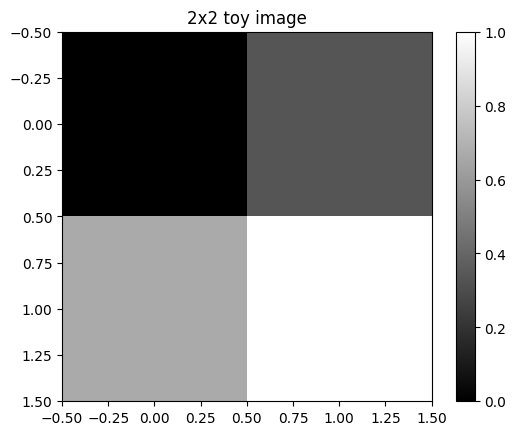

array([[0.    , 0.3333],
       [0.6667, 1.    ]])

In [2]:
img = np.array([[0.0, 1/3], [2/3, 1.0]])        # four grey levels, exactly representable with 2 bits
plt.imshow(img, cmap="gray", vmin=0, vmax=1); plt.title("2x2 toy image"); plt.colorbar(); plt.show()
img

## 2. FRQI

$$|I\rangle = \frac{1}{\sqrt N}\sum_i (\cos\theta_i|0\rangle + \sin\theta_i|1\rangle)\otimes|i\rangle,\qquad \theta_i = \frac{\pi}{2} I_i$$

The circuit applies Hadamards to the position qubits and then a *uniformly controlled* $R_Y(2\theta_i)$ to the
colour qubit. The **optimized** structure uses the Gray-code decomposition (2ⁿ RY + 2ⁿ CNOT). The **baseline**
uses one multi-controlled RY per pixel.

In [3]:
frqi = FRQI()
enc_opt = frqi.encode(img, structure="optimized")
enc_base = frqi.encode(img, structure="baseline")
print(enc_opt.circuit.draw("text"))

        ┌───┐                                               
q_0: ───┤ H ├─────■─────────────────────■───────────────────
        ├───┤     │                     │                   
q_1: ───┤ H ├─────┼────────────────■────┼────────────────■──
     ┌──┴───┴──┐┌─┴─┐┌──────────┐┌─┴─┐┌─┴─┐┌──────────┐┌─┴─┐
q_2: ┤ Ry(π/2) ├┤ X ├┤ Ry(-π/6) ├┤ X ├┤ X ├┤ Ry(-π/3) ├┤ X ├
     └─────────┘└───┘└──────────┘└───┘└───┘└──────────┘└───┘


In [4]:
from qiskit.quantum_info import Statevector
sv = Statevector(enc_opt.circuit).data.real
theta = np.pi / 2 * img.ravel()
expected = np.concatenate([np.cos(theta), np.sin(theta)]) / 2   # basis index = colour*4 + position
print("statevector :", sv)
print("definition  :", expected)
print("max |diff|  :", np.abs(sv - expected).max())

statevector : [0.5   0.433 0.25  0.    0.    0.25  0.433 0.5  ]
definition  : [0.5   0.433 0.25  0.    0.    0.25  0.433 0.5  ]
max |diff|  : 1.1102230246251565e-16


### Decoding: exact probabilities, then finite shots

In [5]:
for shots in [None, 256, 4096, 65536]:
    res = execute(enc_opt.circuit, shots=shots)
    rec, cov = frqi.decode(res.distribution, img.shape, enc_opt)
    print(f"shots={str(shots):>6}  reconstructed={rec.ravel()}  max error={np.abs(rec - img).max():.4f}")

shots=  None  reconstructed=[0.     0.3333 0.6667 1.    ]  max error=0.0000
shots=   256  reconstructed=[0.     0.3455 0.6397 1.    ]  max error=0.0269
shots=  4096  reconstructed=[0.     0.3297 0.659  1.    ]  max error=0.0076
shots= 65536  reconstructed=[0.     0.3338 0.6679 1.    ]  max error=0.0013


FRQI stores intensity in **probability amplitudes**. Every pixel's value is a statistical estimate, and its
error falls roughly as $1/\sqrt{\text{shots per pixel}}$.

## 3. NEQR

$$|I\rangle = \frac{1}{\sqrt N}\sum_i |C_i\rangle\otimes|i\rangle,\qquad C_i\in\{0,1\}^q$$

In [6]:
neqr = NEQR()
levels = images.quantize(img, 2)[1]
print("grey levels:\n", levels)
e = neqr.encode(img, bit_depth=2, structure="baseline")
print(e.circuit.draw("text"))

grey levels:
 [[0 1]
 [2 3]]
     ┌───┐          ┌───┐     ┌───┐          
q_0: ┤ H ├───────■──┤ X ├──■──┤ X ├──■────■──
     ├───┤┌───┐  │  ├───┤  │  └───┘  │    │  
q_1: ┤ H ├┤ X ├──■──┤ X ├──■─────────■────■──
     └───┘└───┘┌─┴─┐└───┘  │       ┌─┴─┐  │  
q_2: ──────────┤ X ├───────┼───────┤ X ├──┼──
               └───┘     ┌─┴─┐     └───┘┌─┴─┐
q_3: ────────────────────┤ X ├──────────┤ X ├
                         └───┘          └───┘


In [7]:
for shots in [None, 8, 64, 1024]:
    res = execute(e.circuit, shots=shots)
    rec, cov = neqr.decode(res.distribution, img.shape, e)
    print(f"shots={str(shots):>5}  coverage={cov:.2f}  reconstructed levels={np.rint(rec.ravel()*3).astype(int)}")

shots= None  coverage=1.00  reconstructed levels=[0 1 2 3]
shots=    8  coverage=1.00  reconstructed levels=[0 1 2 3]
shots=   64  coverage=1.00  reconstructed levels=[0 1 2 3]
shots= 1024  coverage=1.00  reconstructed levels=[0 1 2 3]


NEQR is a **basis** encoding, so one observation of a pixel recovers its grey level exactly. The only
measurement requirement is that every position appears at least once (*coverage*).

## 4. 4×4 natural image, preprocessing included

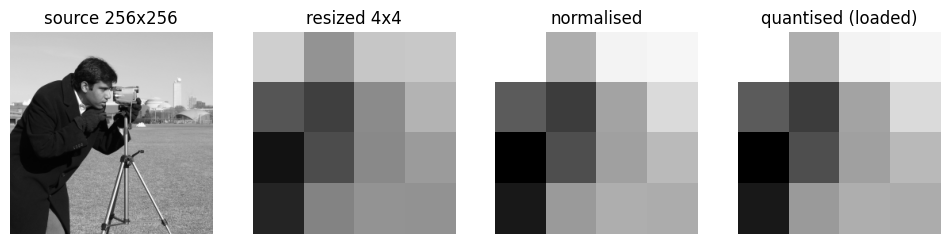

In [8]:
src = images.load_standard("camera")
pre = images.preprocess(src, size=4, interpolation="area", normalization="minmax", bit_depth=8)
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for a, (t, im) in zip(ax, [("source 256x256", src), ("resized 4x4", pre.resized),
                          ("normalised", pre.normalized), ("quantised (loaded)", pre.quantized)]):
    a.imshow(im, cmap="gray", vmin=0, vmax=1); a.set_title(t); a.axis("off")
plt.show()

In [9]:
rows = []
for enc in (FRQI(), NEQR(), Amplitude()):
    for structure in ("baseline", "optimized"):
        e = enc.encode(pre.quantized, 8, structure)
        res = execute(e.circuit, shots=4096, seed=1)
        rec, cov = enc.decode(res.distribution, (4, 4), e)
        rows.append((enc.name, structure, res.qubits, res.cx, res.depth, np.abs(rec - pre.quantized).max()))
import pandas as pd
pd.DataFrame(rows, columns=["encoding", "structure", "qubits", "CNOTs", "depth", "max |error| @4096 shots"])

,encoding,structure,qubits,CNOTs,depth,max |error| @4096 shots
0,frqi,baseline,5,360,663,0.047059
1,frqi,optimized,5,16,80,0.047059
2,neqr,baseline,12,1764,4339,0.000000
3,neqr,optimized,13,842,2047,0.000000
4,amplitude,baseline,4,11,39,0.039883
5,amplitude,optimized,4,11,39,0.039883


**Observations (A1 reflection prompts)**

* The same state can be built with very different circuits. For FRQI the Gray-code multiplexer needs 16 CNOTs,
  while the naive version needs hundreds.
* FRQI uses the fewest qubits but is shot-limited. NEQR uses more qubits and gates but reads out exactly.
* Amplitude encoding (QPIE) uses only log₂N qubits but needs the image norm as classical side-information.